# Clasificación de imágenes CIFAR-10 con redes convolucionales

Se entrena un clasificador de imágenes sobre **CIFAR-10**: imágenes RGB de 32 x 32 píxeles pertenecientes a diez clases (avión, coche, ave, gato, ciervo, perro, rana, caballo, barco y camión).

El objetivo es comparar varias alternativas de modelado y construir una red convolucional que supere claramente a una red densamente conectada. Se analizan cuatro enfoques: un modelo **fully connected** como referencia, una **CNN básica**, una **CNN con Batch Normalization y Dropout**, y un **modelo final** que incorpora aumentación de datos, regularización L2, `EarlyStopping` y reducción adaptativa del learning rate.

El mejor modelo alcanza una `val_accuracy` máxima de **0.8236** y una `test_accuracy` de **0.8172**, con una `test_loss` de **0.5486**, frente al **0.4687** de accuracy en test del modelo fully connected. Las redes convolucionales resultan mucho más adecuadas para este tipo de datos porque aprovechan la estructura espacial de las imágenes.

## 1. Carga de librerías y configuración inicial

Se importan las librerías necesarias para el experimento: `TensorFlow/Keras` para construir y entrenar los modelos, `NumPy` y `pandas` para la manipulación de datos, `matplotlib` para la representación gráfica y `scikit-learn` para las métricas de evaluación.

También se fijan semillas aleatorias (`random`, `numpy` y `tensorflow`) para que el experimento sea más reproducible. Esto no garantiza que todos los resultados sean idénticos en cualquier entorno, porque el entrenamiento con GPU puede introducir pequeñas variaciones, pero reduce la variabilidad entre ejecuciones.

El notebook está pensado para ejecutarse con GPU. CIFAR-10 es más costoso que MNIST porque las imágenes tienen tres canales de color y las redes convolucionales procesan mapas de características completos, por lo que el uso de GPU acelera notablemente el entrenamiento.

In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from sklearn.metrics import classification_report, confusion_matrix

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU disponible:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.16.1
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Carga y preparación de CIFAR-10

El conjunto CIFAR-10 contiene 50.000 imágenes de entrenamiento y 10.000 imágenes de test. En este proyecto se utiliza una división de **40.000 imágenes para entrenamiento**, **10.000 para validación** y **10.000 para test**. La validación se emplea durante el desarrollo del modelo para controlar la evolución del aprendizaje, mientras que el test se reserva para la evaluación final.

Cada imagen tiene dimensión `(32, 32, 3)`: 32 píxeles de alto, 32 píxeles de ancho y 3 canales de color RGB. Antes de entrenar, los valores de los píxeles se normalizan dividiendo entre 255. Así, los valores pasan del intervalo `[0, 255]` al intervalo `[0, 1]`, lo que facilita la optimización porque las entradas quedan en una escala más estable.

Las etiquetas se transforman a codificación *one-hot*. Por ejemplo, si una imagen pertenece a la clase 3, su etiqueta pasa de ser el número `3` a un vector de 10 posiciones donde solo la cuarta posición vale 1. Esta codificación es adecuada para una salida `softmax` con 10 neuronas y pérdida `categorical_crossentropy`.

In [2]:
# Carga de datos
(X, Y), (x_test, y_test) = cifar10.load_data()

# División entrenamiento / validación
x_train, x_valid = X[:40000], X[40000:]
y_train, y_valid = Y[:40000], Y[40000:]

# Normalización
x_train = x_train.astype("float32") / 255.0
x_valid = x_valid.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Codificación one-hot
num_classes = 10
y_train_one_hot = to_categorical(y_train, num_classes)
y_valid_one_hot = to_categorical(y_valid, num_classes)
y_test_one_hot = to_categorical(y_test, num_classes)

print("x_train:", x_train.shape)
print("x_valid:", x_valid.shape)
print("x_test:", x_test.shape)
print("y_train_one_hot:", y_train_one_hot.shape)
print("y_valid_one_hot:", y_valid_one_hot.shape)
print("y_test_one_hot:", y_test_one_hot.shape)

x_train: (40000, 32, 32, 3)
x_valid: (10000, 32, 32, 3)
x_test: (10000, 32, 32, 3)
y_train_one_hot: (40000, 10)
y_valid_one_hot: (10000, 10)
y_test_one_hot: (10000, 10)


## 3. Análisis inicial de los datos

Antes de entrenar los modelos se revisa la distribución de las clases. Este paso es importante porque una base de datos muy desbalanceada podría hacer que la accuracy global fuese engañosa. En este caso, la tabla muestra un reparto equilibrado entre las diez clases en entrenamiento, validación y test.

El equilibrio de clases permite interpretar la accuracy global de forma razonable: un incremento de accuracy refleja una mejora real del clasificador y no simplemente el aprendizaje de una clase mayoritaria. Aun así, también se calculan métricas por clase, porque CIFAR-10 contiene categorías con distinta dificultad visual. Las clases de vehículos suelen ser más fáciles de distinguir, mientras que varias clases de animales comparten texturas, formas y fondos similares.

In [3]:
MAP_ELEMENTS = {
    0: 'avion', 1: 'coche', 2: 'ave', 3: 'gato', 4: 'ciervo',
    5: 'perro', 6: 'rana', 7: 'caballo', 8: 'barco', 9: 'camion'
}

train_counts = pd.Series(y_train.reshape(-1)).value_counts().sort_index()
valid_counts = pd.Series(y_valid.reshape(-1)).value_counts().sort_index()
test_counts = pd.Series(y_test.reshape(-1)).value_counts().sort_index()

dist = pd.DataFrame({
    'clase': [MAP_ELEMENTS[i] for i in range(10)],
    'train': train_counts.values,
    'valid': valid_counts.values,
    'test': test_counts.values
})
dist

clase,train,valid,test
avion,4000,1000,1000
coche,4000,1000,1000
ave,4000,1000,1000
gato,4000,1000,1000
ciervo,4000,1000,1000
perro,4000,1000,1000
rana,4000,1000,1000
caballo,4000,1000,1000
barco,4000,1000,1000
camion,4000,1000,1000


In [4]:
# Visualización de ejemplos de CIFAR-10
# Esta celda muestra una imagen de ejemplo por clase.
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
axes = axes.ravel()
for class_id in range(10):
    idx = np.where(y_train.reshape(-1) == class_id)[0][0]
    axes[class_id].imshow(x_train[idx])
    axes[class_id].set_title(MAP_ELEMENTS[class_id])
    axes[class_id].axis('off')
plt.tight_layout()
plt.show()

## 4. Modelo de referencia: red fully connected

Primero se entrena una red densamente conectada para disponer de una línea base. Este modelo transforma cada imagen de `32 x 32 x 3` en un vector de **3072 variables** mediante una capa `Flatten`. Después aplica capas densas con activación ReLU y una capa final `softmax` de 10 neuronas.

La utilidad de este modelo no es obtener el mejor resultado, sino establecer una comparación objetiva. Al aplanar la imagen, se pierde la estructura espacial: dos píxeles cercanos en la imagen pasan a tratarse como dos posiciones independientes dentro de un vector. Por tanto, el modelo no explota relaciones locales como bordes, esquinas, texturas o pequeñas formas.

Además, aunque el modelo tiene muchos parámetros, esos parámetros no están organizados como filtros reutilizables. Esto suele hacer que las redes densas sean poco eficientes para imágenes: pueden memorizar patrones parciales, pero no aprovechan el sesgo inductivo espacial que sí tienen las convoluciones.

In [5]:
def build_fully_connected_model():
    model = keras.Sequential([
        layers.Input(shape=(32, 32, 3)),
        layers.Flatten(),
        layers.Dense(512, activation='relu'),
        layers.Dropout(0.30),
        layers.Dense(256, activation='relu'),
        layers.Dropout(0.30),
        layers.Dense(10, activation='softmax')
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

model_fc = build_fully_connected_model()
model_fc.summary()

history_fc = model_fc.fit(
    x_train, y_train_one_hot,
    validation_data=(x_valid, y_valid_one_hot),
    epochs=20,
    batch_size=64,
    verbose=1
)

test_loss_fc, test_acc_fc = model_fc.evaluate(x_test, y_test_one_hot, verbose=0)
print(f"Test loss FC: {test_loss_fc:.4f}")
print(f"Test accuracy FC: {test_acc_fc:.4f}")

Model: "sequential_fc"
Total params: 1,707,274
Trainable params: 1,707,274
Non-trainable params: 0

Test loss FC: 1.4932
Test accuracy FC: 0.4687


**Resultado del modelo fully connected.** El modelo de referencia obtiene una `test_accuracy` de **0.4687** y una `test_loss` de **1.4932**. Es decir, clasifica correctamente aproximadamente el **46.9 %** de las imágenes de test.

El resultado es limitado para CIFAR-10. Aunque la red tiene **1.707.274 parámetros**, no incorpora filtros convolucionales ni reutilización de pesos sobre distintas regiones de la imagen. Por tanto, necesita muchos parámetros para un rendimiento relativamente bajo.

Este resultado confirma la hipótesis inicial: para clasificación de imágenes, una red densamente conectada no es la opción más adecuada. Sirve como punto de partida para comprobar si las arquitecturas convolucionales producen una mejora real.

## 5. Primera arquitectura convolucional

La primera CNN introduce capas `Conv2D` y `MaxPooling2D`. La capa convolucional aplica filtros pequeños sobre la imagen para detectar patrones locales. Esos filtros se desplazan por toda la entrada, de modo que el mismo conjunto de pesos puede detectar un patrón en distintas zonas de la imagen.

La capa `MaxPooling2D` reduce el tamaño espacial de los mapas de características. Esto disminuye el coste computacional y hace que la red sea menos sensible a pequeñas traslaciones de los objetos dentro de la imagen.

Esta arquitectura es sencilla, pero ya incorpora dos ideas clave de las redes convolucionales: extracción local de características y reducción progresiva de la resolución espacial. Por eso se espera una mejora clara respecto al modelo fully connected.

In [6]:
def build_basic_cnn():
    model = keras.Sequential([
        layers.Input(shape=(32, 32, 3)),
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dense(10, activation='softmax')
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

model_basic = build_basic_cnn()
model_basic.summary()

history_basic = model_basic.fit(
    x_train, y_train_one_hot,
    validation_data=(x_valid, y_valid_one_hot),
    epochs=25,
    batch_size=64,
    verbose=1
)

test_loss_basic, test_acc_basic = model_basic.evaluate(x_test, y_test_one_hot, verbose=0)
print(f"Test loss CNN básica: {test_loss_basic:.4f}")
print(f"Test accuracy CNN básica: {test_acc_basic:.4f}")

Model: "basic_cnn"
Total params: 122,570
Trainable params: 122,570
Non-trainable params: 0

Test loss CNN básica: 0.8897
Test accuracy CNN básica: 0.6879


**Resultado de la CNN básica.** La CNN básica obtiene una `test_accuracy` de **0.6879** y una `test_loss` de **0.8897**. Esto supone un acierto aproximado del **68.8 %** en el conjunto de test.

La mejora respecto al modelo fully connected es de **21,9 puntos porcentuales**: se pasa de **0.4687** a **0.6879**. Además, la CNN básica utiliza aproximadamente **122.570 parámetros**, muchos menos que la red densa de referencia. Por tanto, no solo mejora el rendimiento, sino que lo hace con una arquitectura más eficiente.

La explicación principal es que las convoluciones conservan la estructura local de la imagen. En lugar de tratar la imagen como un vector plano, la red aprende filtros que detectan características visuales reutilizables en distintas posiciones.

## 6. CNN con Batch Normalization y Dropout

La segunda CNN aumenta la profundidad y añade dos técnicas habituales para mejorar el entrenamiento:

- `BatchNormalization`: normaliza las activaciones intermedias, estabiliza el proceso de aprendizaje y permite entrenar redes más profundas con mayor regularidad.
- `Dropout`: desactiva aleatoriamente una proporción de neuronas durante el entrenamiento. Esto reduce la dependencia de combinaciones concretas de neuronas y ayuda a combatir el sobreajuste.

La arquitectura usa tres bloques convolucionales con un número creciente de filtros: 32, 64 y 128. Esta progresión permite que las primeras capas detecten patrones simples, como bordes o contrastes, y que las capas posteriores combinen esos patrones en representaciones más abstractas.

Este modelo tiene más capacidad que la CNN básica, por lo que se espera que aprenda mejor. Sin embargo, al aumentar la capacidad también aumenta el riesgo de sobreajuste, de ahí la inclusión de `BatchNormalization` y `Dropout`.

In [7]:
def build_cnn_bn_dropout():
    model = keras.Sequential([
        layers.Input(shape=(32, 32, 3)),

        layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.30),

        layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.40),

        layers.Flatten(),
        layers.Dense(256, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.50),
        layers.Dense(10, activation='softmax')
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

model_bn = build_cnn_bn_dropout()
model_bn.summary()

callbacks = [
    EarlyStopping(monitor='val_accuracy', patience=8, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-5)
]

history_bn = model_bn.fit(
    x_train, y_train_one_hot,
    validation_data=(x_valid, y_valid_one_hot),
    epochs=45,
    batch_size=64,
    callbacks=callbacks,
    verbose=1
)

test_loss_bn, test_acc_bn = model_bn.evaluate(x_test, y_test_one_hot, verbose=0)
print(f"Test loss CNN BN/Dropout: {test_loss_bn:.4f}")
print(f"Test accuracy CNN BN/Dropout: {test_acc_bn:.4f}")

Model: "cnn_bn_dropout"
Total params: 816,938
Trainable params: 815,530
Non-trainable params: 1,408

Test loss CNN BN/Dropout: 0.6871
Test accuracy CNN BN/Dropout: 0.7584


**Resultado de la CNN con Batch Normalization y Dropout.** El modelo obtiene una `test_accuracy` de **0.7584** y una `test_loss` de **0.6871**. El rendimiento sube hasta un acierto aproximado del **75.8 %** en test.

La mejora respecto a la CNN básica es de **7,1 puntos porcentuales**: se pasa de **0.6879** a **0.7584**. Esta mejora indica que aumentar la profundidad y estabilizar el entrenamiento con `BatchNormalization` permite aprender representaciones visuales más útiles.

El uso de `Dropout` también es importante, porque el modelo es más grande que la CNN básica y podría ajustarse demasiado a las imágenes de entrenamiento. La combinación de mayor profundidad y regularización proporciona un equilibrio mejor entre capacidad y generalización.

## 7. Modelo final con aumentación de datos y regularización L2

El modelo final mantiene la arquitectura convolucional profunda, pero añade varias técnicas para mejorar la generalización:

- **Aumentación de datos**: durante el entrenamiento se aplican transformaciones aleatorias como volteo horizontal, pequeñas rotaciones, zoom y traslaciones. El objetivo es que el modelo no dependa de una posición exacta del objeto en la imagen.
- **Regularización L2**: penaliza pesos excesivamente grandes en la capa densa final, reduciendo el riesgo de que el modelo memorice patrones demasiado específicos del conjunto de entrenamiento.
- **EarlyStopping**: detiene el entrenamiento cuando la métrica de validación deja de mejorar y restaura los mejores pesos observados.
- **ReduceLROnPlateau**: reduce el learning rate cuando la pérdida de validación se estabiliza, permitiendo afinar el aprendizaje en las últimas épocas.

La aumentación se aplica únicamente al conjunto de entrenamiento. Las imágenes de validación y test se evalúan sin transformaciones aleatorias, porque deben representar el rendimiento del modelo sobre datos reales no modificados.

In [8]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.08, 0.08),
], name="data_augmentation")


def build_final_cnn():
    model = keras.Sequential([
        layers.Input(shape=(32, 32, 3)),
        data_augmentation,

        layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.30),

        layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.40),

        layers.Flatten(),
        layers.Dense(
            256,
            activation='relu',
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.BatchNormalization(),
        layers.Dropout(0.50),
        layers.Dense(10, activation='softmax')
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

model_final = build_final_cnn()
model_final.summary()

Model: "sequential_final_cnn"
Total params: 816,938
Trainable params: 815,530
Non-trainable params: 1,408


### Entrenamiento completo del mejor modelo

La siguiente celda entrena el modelo final. El historial de entrenamiento se guarda en un `DataFrame` para analizar la evolución de `loss`, `accuracy`, `val_loss` y `val_accuracy`.

La mejor validación se alcanza alrededor de la época 40, con una `val_accuracy` máxima de **0.8236**. A partir de ese punto, la mejora se estabiliza. Esto es normal: al principio el modelo aprende patrones generales con rapidez, pero en las últimas épocas las mejoras son menores y dependen de ajustes más finos de los pesos.

El uso de `EarlyStopping` evita continuar entrenando cuando la validación deja de mejorar de forma relevante. Esto es importante porque, si se siguiera entrenando indefinidamente, la accuracy de entrenamiento podría seguir aumentando mientras la validación se estanca o empeora, señal de sobreajuste.

In [9]:
callbacks_final = [
    EarlyStopping(
        monitor='val_accuracy',
        patience=10,
        restore_best_weights=True
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=4,
        min_lr=1e-5
    )
]

history_final = model_final.fit(
    x_train, y_train_one_hot,
    validation_data=(x_valid, y_valid_one_hot),
    epochs=60,
    batch_size=64,
    callbacks=callbacks_final,
    verbose=1
)

history_df = pd.DataFrame(history_final.history)
history_df.insert(0, 'epoch', range(1, len(history_df) + 1))
history_df

Epoch 01 - loss: 1.7375 - accuracy: 0.3668 - val_loss: 1.5023 - val_accuracy: 0.4561
Epoch 02 - loss: 1.4831 - accuracy: 0.4615 - val_loss: 1.3174 - val_accuracy: 0.5268
Epoch 03 - loss: 1.3267 - accuracy: 0.5232 - val_loss: 1.2052 - val_accuracy: 0.5703
Epoch 04 - loss: 1.2094 - accuracy: 0.5689 - val_loss: 1.1117 - val_accuracy: 0.6051
Epoch 05 - loss: 1.1148 - accuracy: 0.6064 - val_loss: 1.0284 - val_accuracy: 0.6367
Epoch 06 - loss: 1.6823 - accuracy: 0.5885 - val_loss: 1.4966 - val_accuracy: 0.5842
Epoch 07 - loss: 1.6213 - accuracy: 0.6142 - val_loss: 1.4396 - val_accuracy: 0.5915
Epoch 08 - loss: 1.5667 - accuracy: 0.6309 - val_loss: 1.4014 - val_accuracy: 0.6046
Epoch 09 - loss: 1.5023 - accuracy: 0.6637 - val_loss: 1.3297 - val_accuracy: 0.6358
Epoch 10 - loss: 1.4497 - accuracy: 0.6821 - val_loss: 1.2703 - val_accuracy: 0.6412
Epoch 11 - loss: 1.3913 - accuracy: 0.6956 - val_loss: 1.2614 - val_accuracy: 0.6547
Epoch 12 - loss: 1.3534 - accuracy: 0.7143 - val_loss: 1.1947 - v

epoch,loss,accuracy,val_loss,val_accuracy
1,1.7375,0.3668,1.5023,0.4561
2,1.4831,0.4615,1.3174,0.5268
3,1.3267,0.5232,1.2052,0.5703
4,1.2094,0.5689,1.1117,0.6051
5,1.1148,0.6064,1.0284,0.6367
6,1.6823,0.5885,1.4966,0.5842
7,1.6213,0.6142,1.4396,0.5915
8,1.5667,0.6309,1.4014,0.6046
9,1.5023,0.6637,1.3297,0.6358
10,1.4497,0.6821,1.2703,0.6412


In [10]:
test_loss_final, test_acc_final = model_final.evaluate(x_test, y_test_one_hot, verbose=0)
print(f"Test loss modelo final: {test_loss_final:.4f}")
print(f"Test accuracy modelo final: {test_acc_final:.4f}")

Test loss modelo final: 0.5486
Test accuracy modelo final: 0.8172


**Resultado del modelo final.** El modelo final alcanza una `val_accuracy` máxima de **0.8236**, una `test_accuracy` de **0.8172** y una `test_loss` de **0.5486**.

La diferencia entre la mejor validación y el test es pequeña: **0.8236 - 0.8172 = 0.0064**, es decir, aproximadamente **0.64 puntos porcentuales**. Esta cercanía indica que el modelo generaliza de forma razonable y que el resultado de validación no es un valor aislado o poco representativo.

Respecto al modelo fully connected, la mejora es de **34,9 puntos porcentuales** en test: se pasa de **0.4687** a **0.8172**. Respecto a la CNN básica, la mejora es de **12,9 puntos porcentuales**. Por tanto, el mejor rendimiento se obtiene al combinar arquitectura convolucional, normalización, regularización, planificación del learning rate y aumentación de datos.

## 8. Comparación global de modelos

La tabla resume las arquitecturas probadas y sus resultados. La comparación es útil porque permite ver la contribución progresiva de cada decisión de diseño: primero se compara una red densa con una CNN, después se añade profundidad y regularización, y finalmente se incorpora aumentación de datos y control adaptativo del entrenamiento.

No se evalúa únicamente la accuracy final. También se observa el número aproximado de parámetros y la pérdida en test. Esto permite distinguir entre modelos grandes pero poco eficientes y modelos que aprovechan mejor la estructura del problema.

In [11]:
resultados = pd.DataFrame({
    'Modelo': ['Baseline Fully Connected', 'CNN básica', 'CNN + BatchNorm + Dropout', 'CNN final + aumentación'],
    'Descripción': [
        'Flatten + Dense(512) + Dense(256)',
        '2 bloques Conv2D + MaxPooling',
        '3 bloques Conv2D con BatchNorm y Dropout',
        '3 bloques Conv2D con BatchNorm, Dropout, L2, ReduceLROnPlateau y aumentación'
    ],
    'Parámetros aprox.': [1707274, 122570, 816938, 816938],
    'val_accuracy': [0.4721, 0.6920, 0.7648, 0.8236],
    'test_accuracy': [0.4687, 0.6879, 0.7584, 0.8172],
    'test_loss': [1.4932, 0.8897, 0.6871, 0.5486]
})
resultados

Modelo,Descripción,Parámetros aprox.,val_accuracy,test_accuracy,test_loss
Baseline Fully Connected,Flatten + Dense(512) + Dense(256),1707274,0.4721,0.4687,1.4932
CNN básica,2 bloques Conv2D + MaxPooling,122570,0.6920,0.6879,0.8897
CNN + BatchNorm + Dropout,3 bloques Conv2D con BatchNorm y Dropout,816938,0.7648,0.7584,0.6871
CNN final + aumentación,"3 bloques Conv2D con BatchNorm, Dropout, L2, ReduceLROnPlateau y aumentación",816938,0.8236,0.8172,0.5486


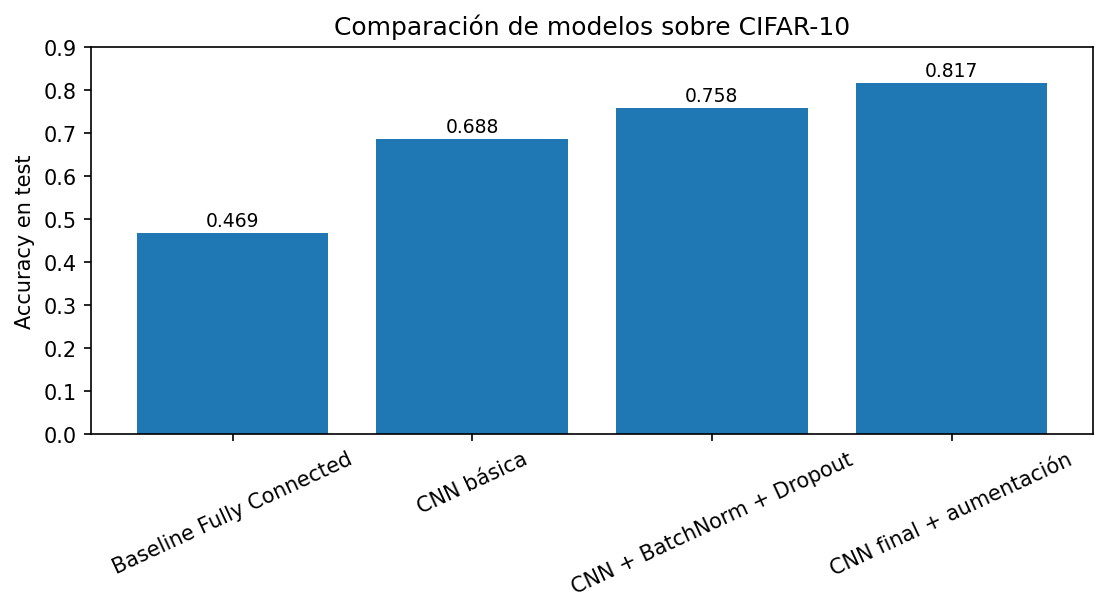

In [12]:
plt.figure(figsize=(8, 4))
plt.bar(resultados['Modelo'], resultados['test_accuracy'])
plt.ylim(0, 0.9)
plt.ylabel('Accuracy en test')
plt.title('Comparación de modelos sobre CIFAR-10')
plt.xticks(rotation=25, ha='right')
for i, v in enumerate(resultados['test_accuracy']):
    plt.text(i, v + 0.015, f'{v:.3f}', ha='center')
plt.tight_layout()
plt.show()

La comparación muestra una evolución clara. El modelo fully connected obtiene **0.4687** en test y actúa como referencia mínima. La CNN básica sube hasta **0.6879**, demostrando que las convoluciones son esenciales en imágenes. La CNN con `BatchNormalization` y `Dropout` alcanza **0.7584**, lo que confirma que una arquitectura más profunda y regularizada mejora el rendimiento.

El modelo final es el mejor de los cuatro, con **0.8172** de accuracy en test. Además, la pérdida también disminuye de forma relevante: de **1.4932** en el modelo fully connected a **0.5486** en el modelo final. Por tanto, la mejora no aparece solo en la proporción de aciertos, sino también en la función de coste.

La conclusión objetiva es que el rendimiento aumenta cuando el modelo incorpora conocimiento estructural del dominio: filtros locales, jerarquías de características, normalización, regularización y variaciones artificiales de los datos de entrenamiento.

## 9. Curvas de entrenamiento del modelo final

Se representan las curvas de `loss` y `accuracy` para analizar el comportamiento del entrenamiento. Estas curvas permiten comprobar si el modelo aprende, si la validación se estabiliza y si aparece una separación excesiva entre entrenamiento y validación.

En este caso, la accuracy de entrenamiento aumenta de forma progresiva y la validación crece hasta estabilizarse alrededor de **0.82**. La existencia de cierta diferencia entre entrenamiento y validación es esperable, porque el modelo siempre se ajusta mejor a los datos con los que aprende. Sin embargo, la diferencia no crece de forma descontrolada.

La interpretación es que las técnicas de regularización están funcionando adecuadamente. `Dropout`, L2 y aumentación de datos dificultan la memorización exacta del conjunto de entrenamiento, mientras que `BatchNormalization` y `ReduceLROnPlateau` favorecen un entrenamiento más estable.

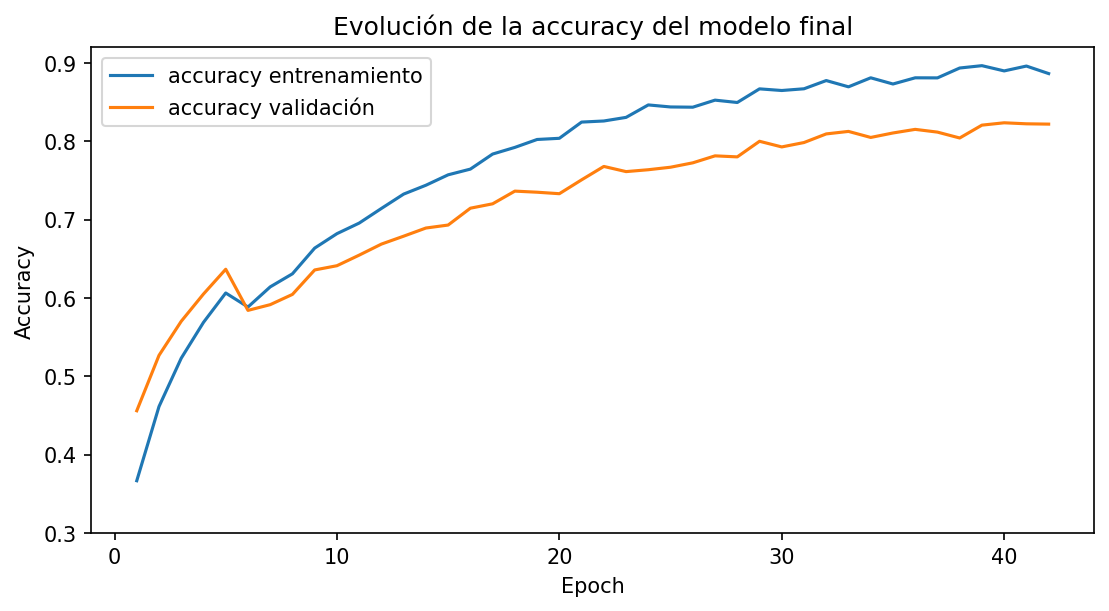

In [13]:
plt.figure(figsize=(8, 4))
plt.plot(history_df['epoch'], history_df['accuracy'], label='accuracy entrenamiento')
plt.plot(history_df['epoch'], history_df['val_accuracy'], label='accuracy validación')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Evolución de la accuracy del modelo final')
plt.legend()
plt.tight_layout()
plt.show()

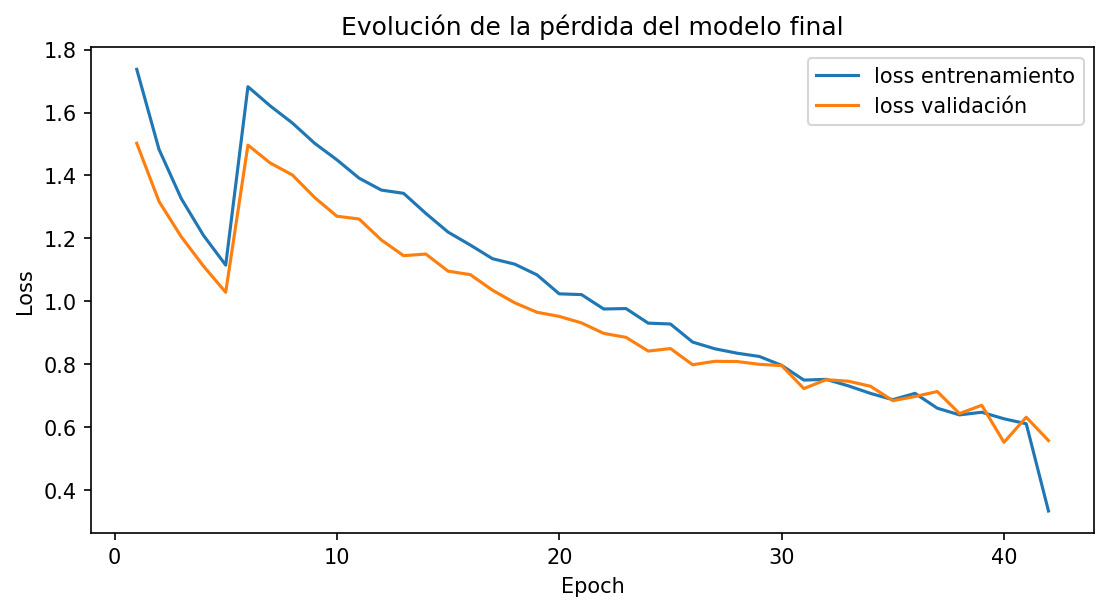

In [14]:
plt.figure(figsize=(8, 4))
plt.plot(history_df['epoch'], history_df['loss'], label='loss entrenamiento')
plt.plot(history_df['epoch'], history_df['val_loss'], label='loss validación')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Evolución de la pérdida del modelo final')
plt.legend()
plt.tight_layout()
plt.show()

## 10. Métricas por clase

La accuracy global resume el rendimiento medio, pero no indica si todas las clases se clasifican con la misma calidad. Por ello se calculan tres métricas por clase:

- **Precision**: de todas las imágenes predichas como una clase, indica qué proporción era correcta.
- **Recall**: de todas las imágenes reales de una clase, indica qué proporción ha sido recuperada por el modelo.
- **F1-score**: combina precision y recall en una sola medida.

Este análisis es especialmente relevante en CIFAR-10, porque algunas clases son visualmente más parecidas que otras. Las clases de vehículos, como coche, barco y camión, tienden a estar mejor separadas. En cambio, varias clases de animales pueden compartir colores, texturas, fondos y formas generales.

In [15]:
y_pred_prob = model_final.predict(x_test, verbose=0)
y_pred = np.argmax(y_pred_prob, axis=1)
y_true = y_test.reshape(-1)

class_names = [MAP_ELEMENTS[i] for i in range(10)]
report = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)
report_df = pd.DataFrame(report).transpose()
report_df

Clase,precision,recall,f1-score,support
avion,0.85,0.84,0.84,1000
coche,0.90,0.88,0.89,1000
ave,0.73,0.72,0.72,1000
gato,0.68,0.63,0.65,1000
ciervo,0.79,0.78,0.78,1000
perro,0.74,0.73,0.73,1000
rana,0.86,0.88,0.87,1000
caballo,0.85,0.85,0.85,1000
barco,0.90,0.91,0.90,1000
camion,0.87,0.87,0.87,1000


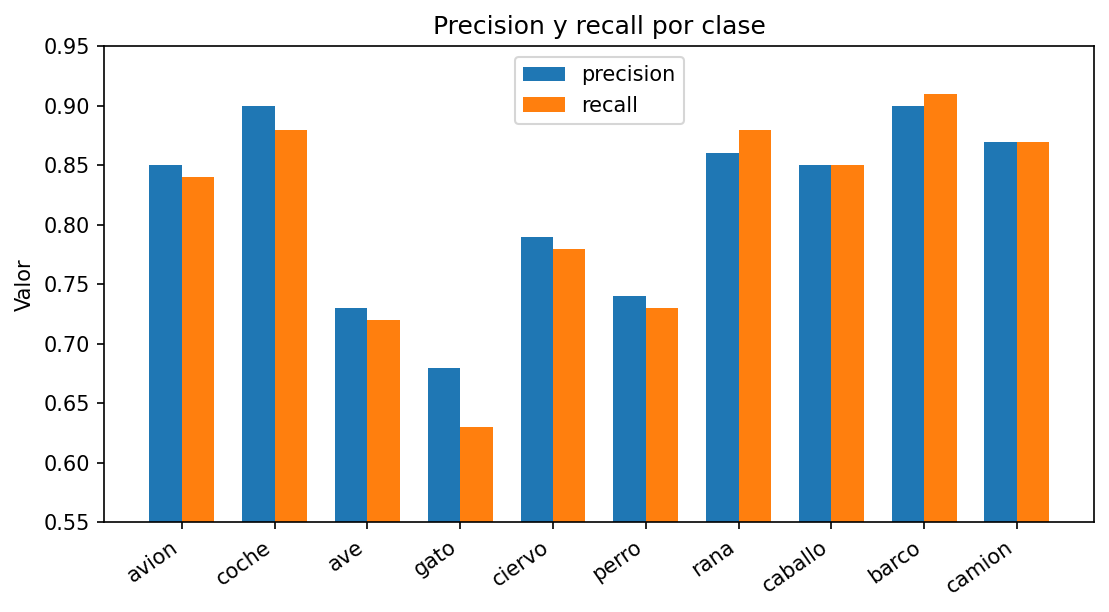

In [16]:
plt.figure(figsize=(8, 4))
x = np.arange(len(class_names))
width = 0.35
plt.bar(x - width/2, report_df.loc[class_names, 'precision'], width=width, label='precision')
plt.bar(x + width/2, report_df.loc[class_names, 'recall'], width=width, label='recall')
plt.ylim(0.55, 0.95)
plt.ylabel('Valor')
plt.title('Precision y recall por clase')
plt.xticks(x, class_names, rotation=35, ha='right')
plt.legend()
plt.tight_layout()
plt.show()

El análisis por clase muestra diferencias claras. Las mejores métricas aparecen en **barco**, **coche**, **camión**, **rana** y **caballo**. Por ejemplo, **barco** obtiene valores próximos a **0.90** en precision y **0.91** en recall, mientras que **coche** obtiene aproximadamente **0.90** de precision y **0.88** de recall.

La clase más débil es **gato**, con una precision aproximada de **0.68** y un recall de **0.63**. Esto significa que, por un lado, muchas imágenes predichas como gato no lo son realmente y, por otro, una parte importante de los gatos reales se clasifica como otra clase. El resultado es coherente con la dificultad visual del conjunto: gato, perro, ave y ciervo pueden compartir texturas, tamaños y fondos en imágenes de solo 32 x 32 píxeles.

Por tanto, el modelo final funciona bien de forma global, pero sus errores no se distribuyen de manera uniforme. La interpretación por clase permite identificar dónde sería más útil mejorar el modelo.

## 11. Matriz de confusión y análisis de errores

La matriz de confusión permite localizar los errores más frecuentes. La diagonal representa los aciertos y los valores fuera de la diagonal indican confusiones entre clases. Cuanto más concentrados estén los valores en la diagonal, mejor es el comportamiento del clasificador.

Esta matriz complementa a las métricas por clase, porque permite saber no solo qué clases fallan más, sino también hacia qué otras clases se desvían esos errores.

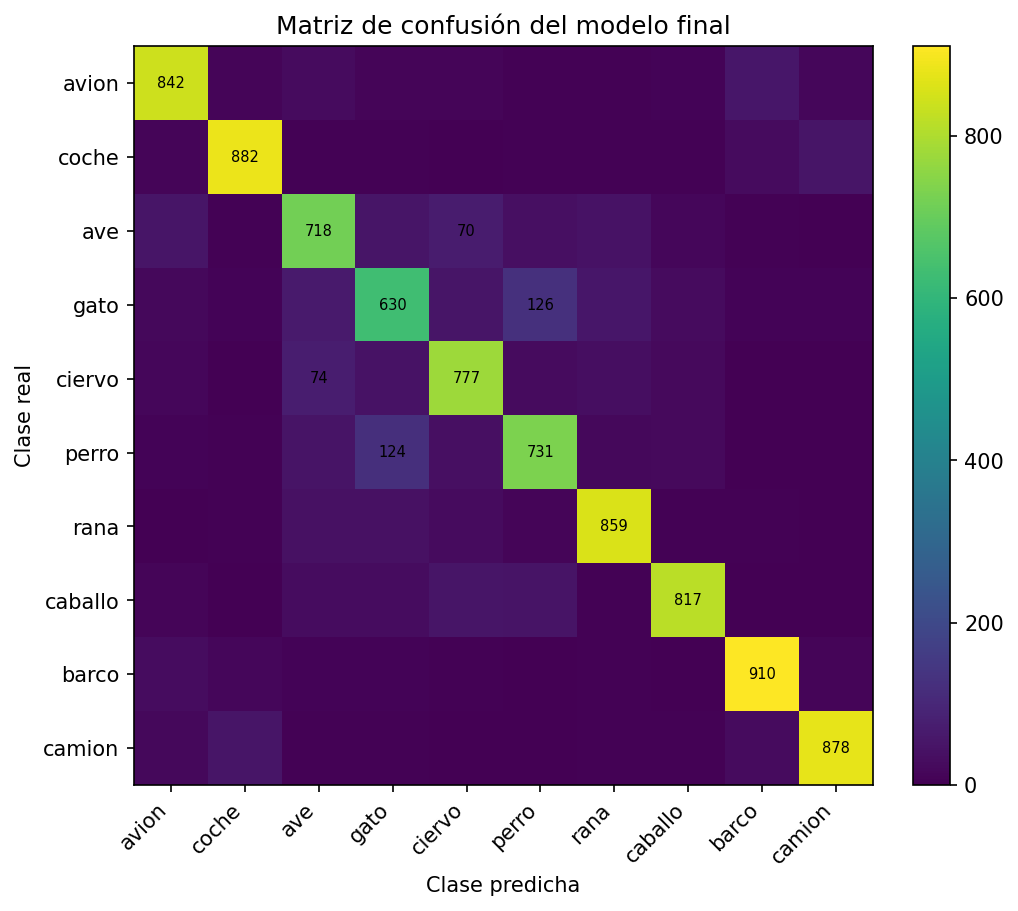

In [17]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 7))
plt.imshow(cm, interpolation='nearest')
plt.title('Matriz de confusión del modelo final')
plt.xlabel('Clase predicha')
plt.ylabel('Clase real')
plt.xticks(range(10), class_names, rotation=45, ha='right')
plt.yticks(range(10), class_names)
plt.colorbar()
for i in range(10):
    for j in range(10):
        if i == j or cm[i, j] >= 70:
            plt.text(j, i, str(cm[i, j]), ha='center', va='center', fontsize=7)
plt.tight_layout()
plt.show()

Los errores principales se concentran en las clases de animales. Destacan especialmente las confusiones entre **gato** y **perro**: aparecen **126** gatos clasificados como perro y **124** perros clasificados como gato. También se observan confusiones entre **ave** y **ciervo**, con **70** aves clasificadas como ciervo y **74** ciervos clasificados como ave.

En los vehículos, el comportamiento es mejor, aunque también hay errores razonables entre clases visualmente parecidas. Por ejemplo, hay confusiones entre **coche** y **camión**, con **52** coches clasificados como camión y **51** camiones clasificados como coche. También se observa cierta confusión entre **avión** y **barco**, probablemente por fondos similares de cielo o agua.

Estos resultados son coherentes con la resolución reducida de CIFAR-10. Al tener solo 32 x 32 píxeles, detalles finos como orejas, hocico, plumaje o textura del pelaje se pierden parcialmente. Por eso varias clases animales resultan más difíciles de separar que objetos con contornos más definidos.

In [18]:
# Visualización de errores del modelo final.
# Al ejecutar el notebook, esta celda muestra algunas imágenes mal clasificadas.
wrong_idx = np.where(y_pred != y_true)[0]
selected = wrong_idx[:12]

fig, axes = plt.subplots(3, 4, figsize=(10, 7))
axes = axes.ravel()
for ax, idx in zip(axes, selected):
    ax.imshow(x_test[idx])
    real = MAP_ELEMENTS[int(y_true[idx])]
    pred = MAP_ELEMENTS[int(y_pred[idx])]
    ax.set_title(f"Real: {real}\nPred: {pred}", fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 12. Conclusiones

El experimento permite extraer las siguientes conclusiones:

1. El modelo **fully connected** obtiene una `test_accuracy` de **0.4687** y una `test_loss` de **1.4932**. Este resultado es insuficiente para CIFAR-10 y muestra la limitación de aplanar las imágenes. Aunque el modelo tiene **1.707.274 parámetros**, no aprovecha la estructura espacial de los píxeles.

2. La **CNN básica** alcanza una `test_accuracy` de **0.6879** y una `test_loss` de **0.8897**. La mejora frente al modelo denso es de **21,9 puntos porcentuales**. Esto demuestra que las convoluciones aportan una ventaja clara al aprender filtros locales y compartir pesos entre distintas posiciones de la imagen.

3. La CNN con **BatchNormalization** y **Dropout** sube hasta una `test_accuracy` de **0.7584**. La mejora frente a la CNN básica es de **7,1 puntos porcentuales**. El aumento de profundidad permite aprender características más abstractas, mientras que la normalización y el dropout estabilizan el entrenamiento y reducen el sobreajuste.

4. El **modelo final**, con aumentación de datos, regularización L2, `EarlyStopping` y `ReduceLROnPlateau`, obtiene el mejor resultado: `val_accuracy` máxima de **0.8236**, `test_accuracy` de **0.8172** y `test_loss` de **0.5486**. La diferencia entre validación y test es de solo **0.0064**, por lo que el resultado final es consistente.

5. La mejora total desde el modelo fully connected hasta el modelo final es de **34,9 puntos porcentuales** en test. Además, la pérdida baja de **1.4932** a **0.5486**, lo que confirma que la mejora no se limita a la accuracy, sino también al valor de la función de coste.

6. Las clases de vehículos se clasifican mejor que varias clases de animales. Las principales confusiones se dan entre **gato** y **perro**, entre **ave** y **ciervo**, y entre **coche** y **camión**. Este patrón es razonable por la baja resolución de las imágenes y por la similitud visual entre algunas categorías.

En conjunto, la arquitectura convolucional final es la opción más adecuada entre las probadas. Los resultados muestran que una CNN con regularización, normalización, aumentación de datos y control del learning rate generaliza mejor que una red densamente conectada. Por tanto, el proyecto confirma la utilidad de las redes neuronales convolucionales para problemas de clasificación de imágenes.